# 2. Análisis exploratorio

El EDA se calcula en `scripts/02_eda.py` con lectura perezosa de Parquet particionado (DuckDB y
Polars), y este capítulo solo lee sus tablas. Las etiquetas del día 30 no se abren aquí: toda tabla
que use `click` cubre los días 21 a 29. La prueba solo entra en comparaciones sin etiqueta
(PSI y categorías no vistas).

In [1]:
import sys
sys.path.insert(0, "../src")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, json
from ctr.plots import C, style, es, miles
from ctr.config import RES
style()
E = RES / "eda"
pd.set_option("display.max_columns", 30)

## 2.1 Carga eficiente, tipos y valores faltantes

El CSV ocupa 6,3 GB y el Parquet con ZSTD 1,22 GB, una quinta parte. La tabla compara el mismo
agregado (tasa de clics por `site_category`) sobre los 40,4 millones de filas.

In [2]:
b = pd.read_json(RES / "bench" / "ingest.jsonl", lines=True).drop_duplicates(["step", "engine"], keep="last")
t = b[b.step.isin(["agg_csv", "agg_parquet"])].pivot(index="engine", columns="step", values="sec").round(2)
t.columns = ["CSV (s)", "Parquet (s)"]
t.loc["pandas (solo 32,4 M y 2 columnas)"] = [round(b[b.step == "agg_csv_2col_train"].sec.iloc[0], 2), np.nan]
t

,CSV (s),Parquet (s)
engine,,
duckdb,5.12,0.10
polars,8.31,0.27
spark,22.68,6.51
"pandas (solo 32,4 M y 2 columnas)",56.01,NaN


In [3]:
nul = pd.read_csv(E / "nulos.csv", index_col=0)
tipos = pd.read_csv(E / "tipos.csv")
print("Columnas:", len(tipos), "| nulos en total:", int(nul.nulos.sum()))
print(tipos.tipo.value_counts().to_string())

Columnas: 27 | nulos en total: 0
tipo
String     22
Int32       3
Float64     1
Int64       1


No hay nulos, pero tampoco tipos con significado: casi todo viene anonimizado, incluso los campos
`C1` y `C14` a `C21`. Por eso `C14` a `C21` se tratan como categóricas aunque parezcan números.
El valor `-1` de `C20` funciona como centinela de dato ausente y se conserva como una categoría más.

## 2.2 Tasa base por día, hora y franja

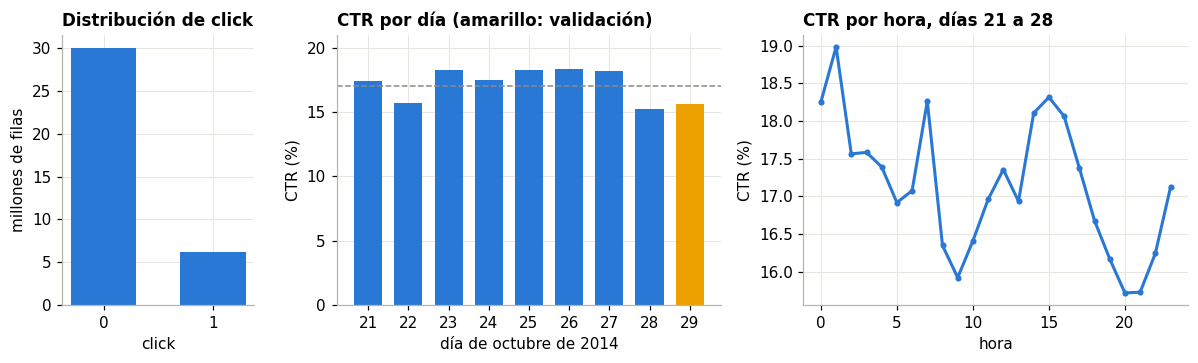

Tasa base días 21 a 29: 16,99 %


,n,ctr
franja,,
madrugada,6476200,0.1761
manana,9904430,0.1677
noche,5555868,0.1629
tarde,10440923,0.1767


In [4]:
dia = pd.read_csv(E / "ctr_dia.csv"); h = pd.read_csv(E / "ctr_hora.csv"); fr = pd.read_csv(E / "ctr_franja.csv")
ck = pd.read_csv(E / "click.csv").sort_values("click")
fig, ax = plt.subplots(1, 3, figsize=(11, 3.4), gridspec_kw=dict(width_ratios=[.6, 1.2, 1.2]))
ax[0].bar(["0", "1"], ck.n / 1e6, color=C["azul"], width=.6)
ax[0].set(title="Distribución de click", ylabel="millones de filas", xlabel="click")
ax[1].bar(dia.day.astype(str), dia.ctr * 100, color=[C["azul"]] * 8 + [C["amarillo"]], width=.7)
ax[1].axhline(np.average(dia.ctr, weights=dia.n) * 100, color=C["gris"], lw=1, ls="--")
ax[1].set(title="CTR por día (amarillo: validación)", ylabel="CTR (%)", xlabel="día de octubre de 2014", ylim=(0, 21))
ax[2].plot(h.hod, h.ctr * 100, color=C["azul"], marker="o", ms=3)
ax[2].set(title="CTR por hora, días 21 a 28", xlabel="hora", ylabel="CTR (%)")
plt.tight_layout(); plt.show()
print(f"Tasa base días 21 a 29: {es(ck[ck.click == 1].n.iloc[0] / ck.n.sum() * 100, 2)} %")
fr.assign(ctr=lambda d: d.ctr.round(4)).set_index("franja")

La tasa cae cerca de dos puntos los días 22 y 28, y también el 29, justo antes de la prueba. El nivel
de CTR cambia de un día a otro más que dentro del día. Esa es la razón para dividir por tiempo: una
partición aleatoria mezclaría días y ocultaría esa variación.

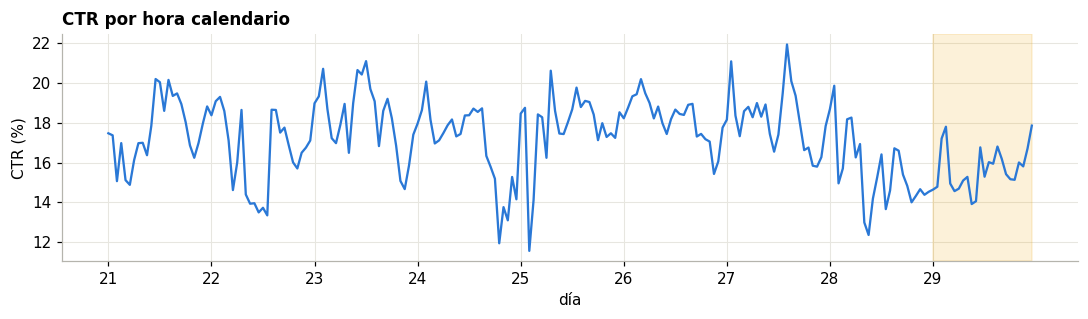

In [5]:
dh = pd.read_csv(E / "ctr_dia_hora.csv").assign(t=lambda d: (d.day - 21) * 24 + d.hod)
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(dh.t, dh.ctr * 100, color=C["azul"], lw=1.5)
ax.set_xticks(range(0, 216, 24), range(21, 30))
ax.axvspan(192, 215, color=C["amarillo"], alpha=.15)
ax.set(title="CTR por hora calendario", xlabel="día", ylabel="CTR (%)"); plt.tight_layout(); plt.show()

## 2.3 Cardinalidad y cola larga

In [6]:
c = pd.read_csv(E / "cardinalidad.csv").sort_values("categorias", ascending=False)
t = c.head(8)[["col", "categorias", "pct_cat_singleton", "pct_filas_singleton", "pct_filas_rara", "top1"]].copy()
t.columns = ["Variable", "Categorías", "% cat. vistas una vez", "% filas de esas cat.", "% filas raras (<10)", "% filas top 1"]
for k in t.columns[2:]:
    t[k] = (t[k] * 100).round(1)
t.set_index("Variable")

,Categorías,% cat. vistas una vez,% filas de esas cat.,% filas raras (<10),% filas top 1
Variable,,,,,
device_ip,5566572,49.9,8.6,34.6,0.5
device_id,2217500,63.1,4.3,11.8,82.6
app_id,8095,19.9,0.0,0.0,65.3
device_model,8036,9.8,0.0,0.0,6.1
site_domain,7299,24.8,0.0,0.0,36.0
site_id,4551,11.5,0.0,0.0,34.7
C14,2252,2.0,0.0,0.0,2.5
app_domain,539,25.0,0.0,0.0,68.8


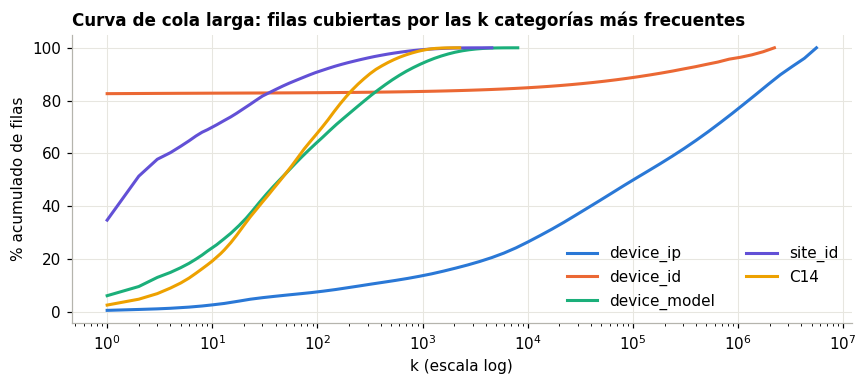

In [7]:
cl = pd.read_csv(E / "cola_larga.csv")
fig, ax = plt.subplots(figsize=(8, 3.6))
for col, co in [("device_ip", C["azul"]), ("device_id", C["naranja"]), ("device_model", C["aqua"]), ("site_id", C["violeta"]), ("C14", C["amarillo"])]:
    d = cl[cl.col == col]
    ax.plot(d.n_cat, d.cum * 100, color=co, label=col)
ax.set_xscale("log"); ax.legend(ncol=2)
ax.set(title="Curva de cola larga: filas cubiertas por las k categorías más frecuentes", xlabel="k (escala log)", ylabel="% acumulado de filas")
plt.tight_layout(); plt.show()

`device_ip` y `device_id` concentran el problema: 5,6 y 2,2 millones de categorías. Una columna
one-hot por valor es inviable, como advierte el enunciado. `device_id` además engaña: su valor
más común cubre el 82,6 % de las filas y funciona como "sin identificador". El umbral de 10
apariciones manda a `__RARE__` el 34,6 % de las filas en `device_ip`, pero casi ninguna en las demás.

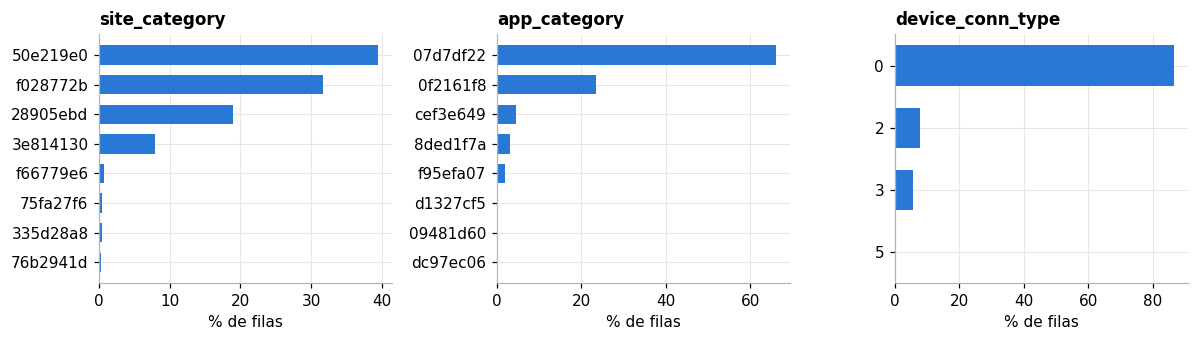

In [8]:
tc = pd.read_csv(E / "top_categorias.csv")
fig, axs = plt.subplots(1, 3, figsize=(11, 3.2))
for a, col in zip(axs, ["site_category", "app_category", "device_conn_type"]):
    d = tc[tc.col == col].head(8).iloc[::-1]
    a.barh(d.v.astype(str).str[:8], d.share * 100, color=C["azul"], height=.65)
    a.set(title=col, xlabel="% de filas")
plt.tight_layout(); plt.show()

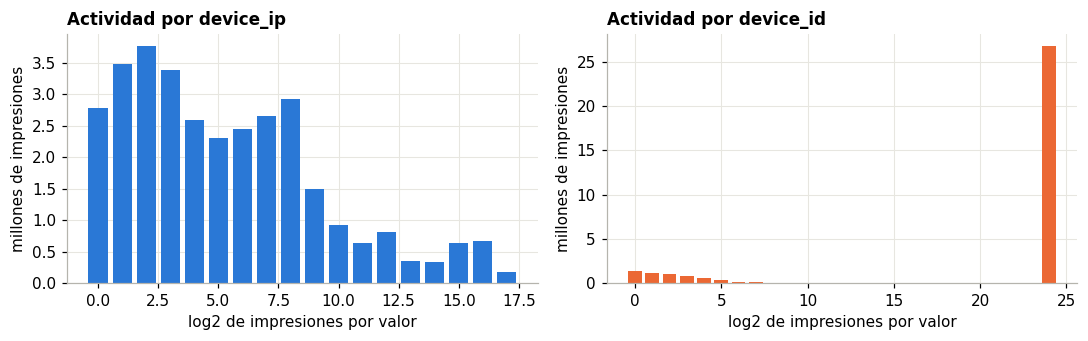

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.2))
for a, col, co in zip(axs, ["device_ip", "device_id"], [C["azul"], C["naranja"]]):
    d = pd.read_csv(E / f"hist_actividad_{col}.csv")
    a.bar(d.b, d.impresiones / 1e6, color=co, width=.8)
    a.set(title=f"Actividad por {col}", xlabel="log2 de impresiones por valor", ylabel="millones de impresiones")
plt.tight_layout(); plt.show()

Estos conteos son la numérica de cola pesada. Por eso entran al modelo con `log1p` y `StandardScaler`.

## 2.4 Asociación con click y correlación

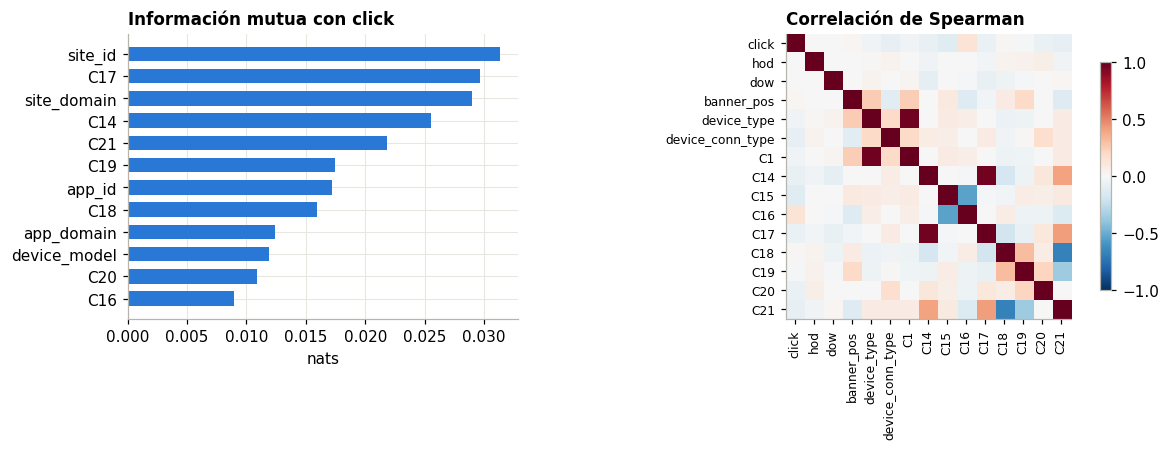

,mi,cramer_v,n
col,,,
site_id,0.0313,0.2606,1617722
C17,0.0297,0.2467,1617722
site_domain,0.0290,0.2497,1617722
C14,0.0255,0.2292,1617722
C21,0.0218,0.2026,1617722
C19,0.0174,0.1770,1617722


In [10]:
a = pd.read_csv(E / "asociacion.csv").head(12).iloc[::-1]
sp = pd.read_csv(E / "spearman.csv", index_col=0)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw=dict(width_ratios=[.8, 1.2]))
ax[0].barh(a.col, a.mi, color=C["azul"], height=.65)
ax[0].set(title="Información mutua con click", xlabel="nats")
im = ax[1].imshow(sp.values, vmin=-1, vmax=1, cmap="RdBu_r")
ax[1].set_xticks(range(len(sp)), sp.columns, rotation=90, fontsize=8); ax[1].set_yticks(range(len(sp)), sp.index, fontsize=8)
ax[1].grid(False); ax[1].set_title("Correlación de Spearman"); fig.colorbar(im, ax=ax[1], shrink=.8)
plt.tight_layout(); plt.show()
pd.read_csv(E / "asociacion.csv").head(6).round(4).set_index("col")

La muestra para asociación es el 5 % del entrenamiento (1,6 millones), con las 100 categorías más
frecuentes de cada variable. Ninguna variable sola explica mucho: la mayor V de Cramér ronda 0,26. Los
campos anónimos `C17`, `C14` y `C21` compiten con `site_id`, y `C14` a `C17` guardan correlaciones
altas entre sí, posible señal de que describen el mismo anuncio.

## 2.5 Deriva: PSI entre entrenamiento y prueba

El PSI usa solo la distribución de las variables, sin etiquetas: 20 categorías principales del
entrenamiento más `otros`. Como referencia usual, más de 0,25 ya es deriva importante.

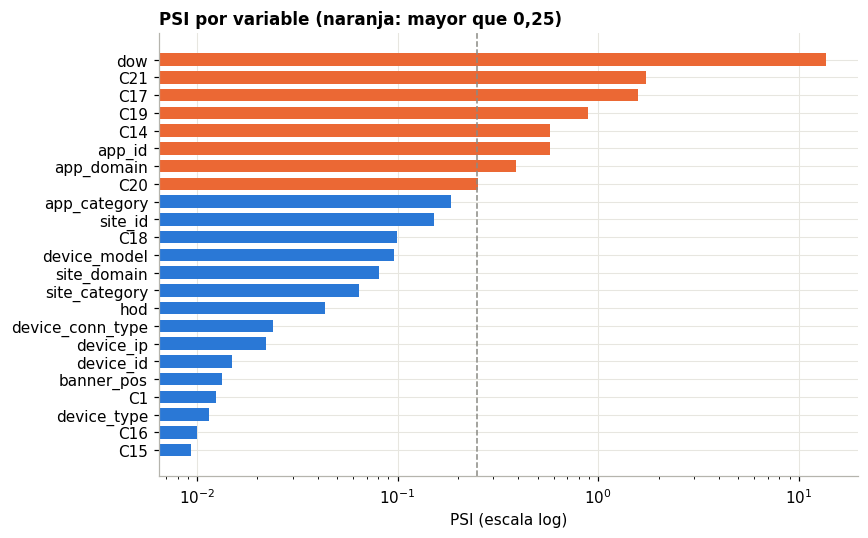

,% filas de prueba no vistas
col,
device_ip,44.6
C14,36.0
C17,33.6
C21,19.3
C19,10.4
device_id,10.3


In [11]:
p = pd.read_csv(E / "psi.csv").sort_values("psi")
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(p.col, p.psi, color=[C["naranja"] if x > .25 else C["azul"] for x in p.psi], height=.7)
ax.set_xscale("log"); ax.axvline(.25, color=C["gris"], ls="--", lw=1)
ax.set(title="PSI por variable (naranja: mayor que 0,25)", xlabel="PSI (escala log)")
plt.tight_layout(); plt.show()
nv = pd.read_csv(E / "no_vistas.csv"); nv = nv[nv.split == "test"].sort_values("pct_filas_no_vistas", ascending=False).head(6)
nv.assign(pct=lambda d: (d.pct_filas_no_vistas * 100).round(1))[["col", "pct"]].rename(columns={"pct": "% filas de prueba no vistas"}).set_index("col")

`dow` tiene un PSI enorme por construcción: la prueba es un solo jueves, y el entrenamiento reparte
ocho días, así que este valor describe el diseño y no un cambio de comportamiento. Lo informativo es
otra cosa: `C21`, `C17`, `C19` y `C14` superan 0,5, y el 36 % de las filas de prueba trae un `C14`
que el entrenamiento nunca vio. `C14` y `C17` parecen identificar creatividades que rotan en el
tiempo. Una división aleatoria nunca dejaría ver esto.

**Qué se llevan los siguientes capítulos:**

- La división temporal no es un formalismo: la deriva es grande.
- Hay que tratar categorías no vistas, porque aparecen en más del 40 % de las filas para `device_ip`.
- `device_ip`, `device_id`, `C14` y `C17` definen el costo de la codificación.